In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "stockwise.db").exists():
    ROOT = ROOT.parent

con = sqlite3.connect(ROOT / "stockwise.db")
sales = pd.read_sql_query(
    "SELECT sale_date, product_id, category, qty FROM sales_enriched",
    con, parse_dates=["sale_date"])


dead_ids = pd.read_csv(ROOT / "data" / "dead_stock.csv")["product_id"]
sales = sales[~sales["product_id"].isin(dead_ids)]
print(sales.shape, "| dead-stock products excluded:", len(dead_ids))

(327026, 4) | dead-stock products excluded: 8


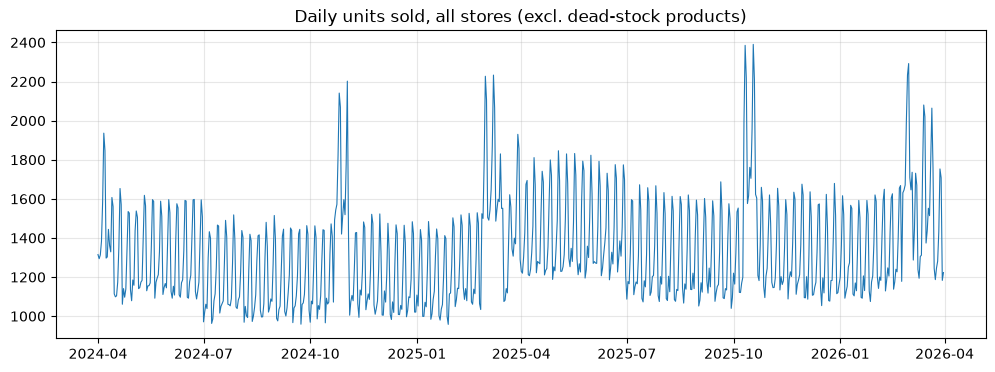

count     730.0
mean     1330.0
std       259.0
min       958.0
25%      1121.0
50%      1268.0
75%      1509.0
max      2390.0
Name: qty, dtype: float64

In [2]:
daily = sales.groupby("sale_date")["qty"].sum().asfreq("D")
assert len(daily) == 730 and daily.isna().sum() == 0, "Missing days in the series"

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, lw=0.8)
ax.set_title("Daily units sold, all stores (excl. dead-stock products)")
ax.grid(alpha=0.3)
plt.show()
daily.describe().round(0)

In [3]:
train = daily[:"2025-12-31"]
test = daily["2026-01-01":]
assert len(train) == 640 and len(test) == 90
print("train:", train.index.min().date(), "to", train.index.max().date())
print("test: ", test.index.min().date(), "to", test.index.max().date())

train: 2024-04-01 to 2025-12-31
test:  2026-01-01 to 2026-03-31


In [4]:
b1 = pd.Series(np.tile(train.values[-7:], 13)[:90], index=test.index)

wd_avg = train[-56:].groupby(train[-56:].index.dayofweek).mean()
b2 = pd.Series(test.index.dayofweek.map(wd_avg).values, index=test.index)

def score(actual, pred):
    err = pred - actual
    return {"MAE (units/day)": round(err.abs().mean(), 1),
            "WAPE %": round(100 * err.abs().sum() / actual.sum(), 1),
            "Bias %": round(100 * err.sum() / actual.sum(), 1)}

results = pd.DataFrame({"Repeat last week": score(test, b1),
                        "8-week weekday average": score(test, b2)}).T
results

C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\4154121144.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  wd_avg = train[-56:].groupby(train[-56:].index.dayofweek).mean()
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\4154121144.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  b2 = pd.Series(test.index.dayofweek.map(wd_avg).values, index=test.index)


,MAE (units/day),WAPE %,Bias %
Repeat last week,142.6,10.0,-8.2
8-week weekday average,140.6,9.8,-8.8


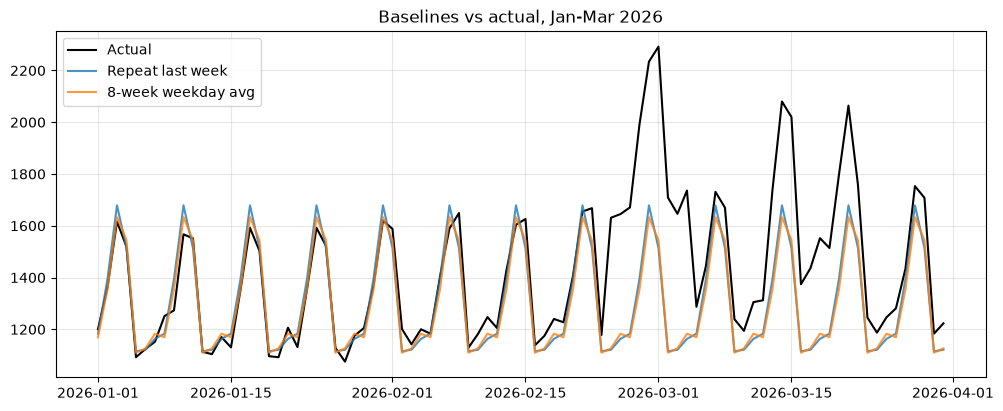

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(test.index, test.values, label="Actual", color="black")
ax.plot(b1.index, b1.values, label="Repeat last week", alpha=0.8)
ax.plot(b2.index, b2.values, label="8-week weekday avg", alpha=0.8)
ax.set_title("Baselines vs actual, Jan-Mar 2026")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(ROOT / "images" / "06_baselines.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
import statsmodels.api as sm

festivals = {
    "diwali": [("2024-10-22", "2024-11-02"), ("2025-10-10", "2025-10-21")],
    "holi":   [("2025-02-26", "2025-03-14"), ("2026-02-24", "2026-03-04")],
    "eid":    [("2024-04-01", "2024-04-11"), ("2025-03-24", "2025-03-31"),
               ("2026-03-13", "2026-03-21")],
    "navratri": [("2024-10-03", "2024-10-12"), ("2025-09-22", "2025-10-01")],
}
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def make_features(idx):
    X = pd.DataFrame(index=idx)
    X["t_years"] = (idx - pd.Timestamp("2024-04-01")).days / 365
    for name, windows in festivals.items():
        X[name] = 0
        for start, end in windows:
            X.loc[(idx >= start) & (idx <= end), name] = 1
    X["summer"] = idx.month.isin([4, 5, 6]).astype(int)
    for d in range(1, 7):                       
        X[day_names[d]] = (idx.dayofweek == d).astype(int)
    return sm.add_constant(X.astype(float), has_constant="add")

X_train, X_test = make_features(train.index), make_features(test.index)
print(X_train.shape, X_test.shape)              
print(X_train[["diwali", "holi", "eid"]].sum())  

(640, 13) (90, 13)
diwali    24.0
holi      17.0
eid       19.0
dtype: float64


C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).asty

In [7]:
model = sm.GLM(train.astype(float).values, X_train, family=sm.families.Poisson()).fit()

ci = model.conf_int()
coef = pd.DataFrame({"multiplier": np.exp(model.params),
                     "low": np.exp(ci.iloc[:, 0]),
                     "high": np.exp(ci.iloc[:, 1])}).round(3)
coef

,multiplier,low,high
const,967.237,959.707,974.826
t_years,1.096,1.091,1.101
diwali,1.448,1.434,1.462
holi,1.422,1.405,1.439
eid,1.213,1.198,1.227
navratri,0.990,0.977,1.003
summer,1.134,1.128,1.140
Tue,1.007,0.999,1.016
Wed,1.058,1.049,1.067
Thu,1.057,1.048,1.066


In [8]:
pred = pd.Series(model.predict(X_test), index=test.index)

results.loc["Poisson GLM"] = pd.Series(score(test, pred))
results


,MAE (units/day),WAPE %,Bias %
Repeat last week,142.6,10.0,-8.2
8-week weekday average,140.6,9.8,-8.8
Poisson GLM,44.4,3.1,0.2


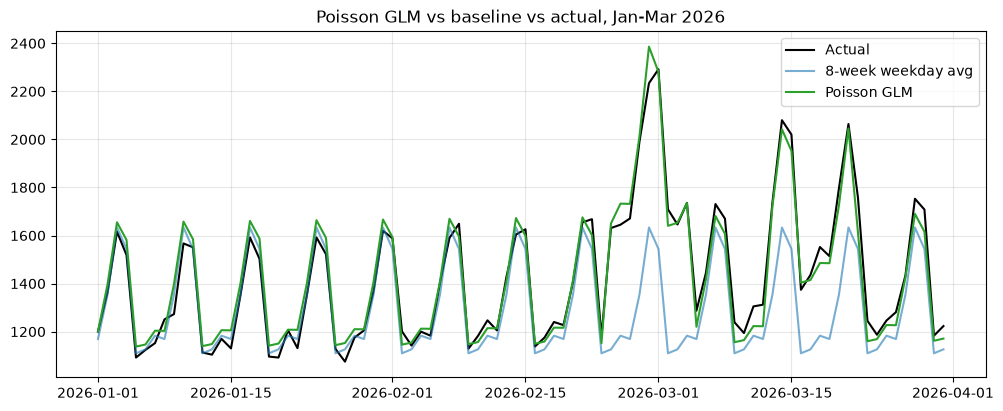

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(test.index, test.values, label="Actual", color="black")
ax.plot(b2.index, b2.values, label="8-week weekday avg", alpha=0.6)
ax.plot(pred.index, pred.values, label="Poisson GLM", color="tab:green")
ax.set_title("Poisson GLM vs baseline vs actual, Jan-Mar 2026")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(ROOT / "images" / "07_glm_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
results.sort_values("WAPE %")

,MAE (units/day),WAPE %,Bias %
Poisson GLM,44.4,3.1,0.2
8-week weekday average,140.6,9.8,-8.8
Repeat last week,142.6,10.0,-8.2


In [11]:
res = pd.DataFrame({"actual": test, "pred": pred})

by_month = res.groupby(res.index.month)[["actual", "pred"]].sum()
by_month["bias_%"] = (100 * (by_month["pred"] - by_month["actual"]) / by_month["actual"]).round(1)
print(by_month.round(0), "\n")

wd = res.groupby(res.index.dayofweek)[["actual", "pred"]].sum()
wd.index = day_names
wd["bias_%"] = (100 * (wd["pred"] - wd["actual"]) / wd["actual"]).round(1)
print(wd.round(0), "\n")


print("dispersion:", round(model.pearson_chi2 / model.df_resid, 2))

           actual     pred  bias_%
sale_date                         
1           40236  41666.0     4.0
2           40237  40500.0     1.0
3           48159  46739.0    -3.0 

     actual     pred  bias_%
Mon   15825  15678.0    -1.0
Tue   16211  16289.0     0.0
Wed   15874  15875.0     0.0
Thu   16597  16553.0    -0.0
Fri   19353  19542.0     1.0
Sat   22698  23167.0     2.0
Sun   22074  21801.0    -1.0 

dispersion: 1.17


C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\1194225682.py:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  wd = res.groupby(res.index.dayofweek)[["actual", "pred"]].sum()


In [12]:
X_all = make_features(daily.index)
final = sm.GLM(daily.astype(float).values, X_all, family=sm.families.Poisson()).fit()

future = pd.date_range("2026-04-01", "2026-04-30")
X_future = make_features(future)
assert list(X_future.columns) == list(X_all.columns)
mean_fc = pd.Series(final.predict(X_future), index=future)


rng = np.random.default_rng(1)
sim = rng.poisson(mean_fc.values, size=(5000, len(future)))
fc = pd.DataFrame({"forecast": mean_fc.round(0),
                   "low_10%": np.percentile(sim, 10, axis=0),
                   "high_90%": np.percentile(sim, 90, axis=0)})
fc.index.name = "date"
print("April 2026 total forecast units:", int(fc["forecast"].sum()))
fc.head(10)

April 2026 total forecast units:

C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).asty

 46169


,forecast,low_10%,high_90%
date,,,
2026-04-01,1395.0,1347.0,1441.0
2026-04-02,1394.0,1346.0,1441.0
2026-04-03,1618.0,1568.0,1669.0
2026-04-04,1915.0,1860.0,1970.0
2026-04-05,1839.0,1784.0,1895.0
2026-04-06,1322.0,1275.0,1367.0
2026-04-07,1329.0,1283.0,1376.0
2026-04-08,1397.0,1349.9,1445.0
2026-04-09,1397.0,1350.0,1446.0


In [13]:
sim_t = rng.poisson(pred.values, size=(5000, len(test)))
lo, hi = np.percentile(sim_t, 10, axis=0), np.percentile(sim_t, 90, axis=0)
print("share of test days inside the 80% range:", round(((test.values >= lo) & (test.values <= hi)).mean() * 100), "%")

share of test days inside the 80% range: 56 %


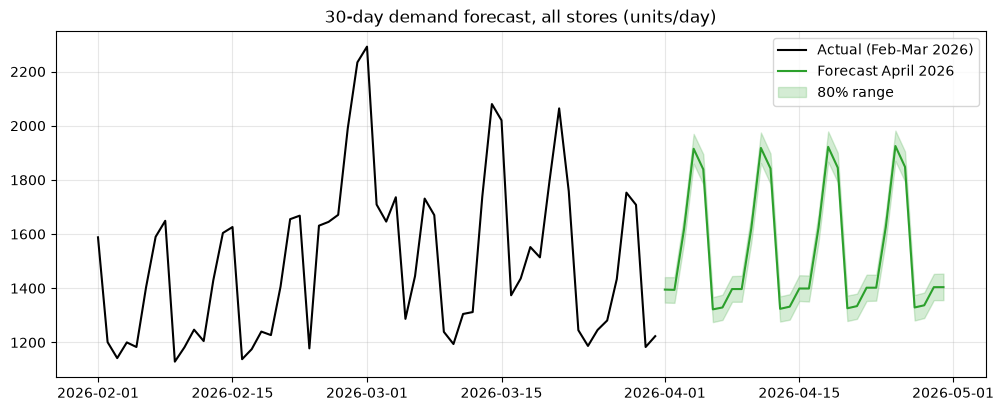

In [14]:
fig, ax = plt.subplots(figsize=(12, 4.5))
hist = daily["2026-02-01":]
ax.plot(hist.index, hist.values, color="black", label="Actual (Feb-Mar 2026)")
ax.plot(fc.index, fc["forecast"], color="tab:green", label="Forecast April 2026")
ax.fill_between(fc.index, fc["low_10%"], fc["high_90%"], color="tab:green", alpha=0.2, label="80% range")
ax.set_title("30-day demand forecast, all stores (units/day)")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(ROOT / "images" / "08_forecast_april2026.png", dpi=150, bbox_inches="tight")
plt.show()

fc.reset_index().to_csv(ROOT / "data" / "forecast_next30.csv", index=False)

In [15]:
cat_daily = (sales.groupby(["category", "sale_date"])["qty"].sum()
                  .unstack("category").asfreq("D").fillna(0))
cats = list(cat_daily.columns)
print(cat_daily.shape)          

(730, 8)


In [16]:
X_tr = make_features(cat_daily[:"2025-12-31"].index)
X_te = make_features(cat_daily["2026-01-01":].index)
bt = []
for c in cats:
    m = sm.GLM(cat_daily.loc[:"2025-12-31", c].astype(float).values, X_tr,
               family=sm.families.Poisson()).fit()
    p = m.predict(X_te)
    a = cat_daily.loc["2026-01-01":, c].values
    bt.append({"category": c,
               "WAPE %": round(100 * np.abs(p - a).sum() / a.sum(), 1),
               "Bias %": round(100 * (p - a).sum() / a.sum(), 1)})
pd.DataFrame(bt).set_index("category")

C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).asty

,WAPE %,Bias %
category,,
Beverages,14.4,-1.2
Dairy,4.1,0.3
Household,7.0,0.6
Packaged Foods,8.6,0.3
Personal Care,9.8,-1.9
Snacks,3.8,0.8
Staples & Grains,6.0,0.0
Stationery,10.7,6.1


In [17]:
X_all = make_features(cat_daily.index)
X_future = make_features(future)          # April 2026, defined in Cell 12
rows = []
for c in cats:
    m = sm.GLM(cat_daily[c].astype(float).values, X_all, family=sm.families.Poisson()).fit()
    april = pd.Series(m.predict(X_future)).mean()
    recent = cat_daily.loc["2026-01-01":, c].mean()
    rows.append({"category": c, "jan_mar_avg": round(recent, 1),
                 "april_forecast_avg": round(april, 1), "uplift": round(april / recent, 2)})
uplift = pd.DataFrame(rows).set_index("category")
uplift

C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).astype(int)
C:\Users\Hp\AppData\Local\Temp\ipykernel_11908\2902872640.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X[day_names[d]] = (idx.dayofweek == d).asty

,jan_mar_avg,april_forecast_avg,uplift
category,,,
Beverages,246.6,347.9,1.41
Dairy,308.8,287.3,0.93
Household,85.4,87.8,1.03
Packaged Foods,93.0,86.0,0.92
Personal Care,68.2,68.1,1.00
Snacks,432.0,407.1,0.94
Staples & Grains,141.2,137.0,0.97
Stationery,54.1,115.8,2.14


In [18]:
r = pd.read_csv(ROOT / "data" / "reorder_analysis.csv")
prod = pd.read_sql_query("SELECT product_id, unit_cost, shelf_life_days FROM products", con)
r = (r.merge(prod, on="product_id")
      .merge(uplift[["uplift"]], left_on="category", right_index=True))

REVIEW_DAYS = 7                                    
shelf = r["shelf_life_days"].fillna(10**6)
cover = np.minimum(r["avg_lead_time_days"] + REVIEW_DAYS,
                   np.maximum(r["avg_lead_time_days"], 0.8 * shelf))   

r["forecast_daily"] = r["avg_daily"] * r["uplift"]
r["target_stock"] = np.ceil(r["forecast_daily"] * cover + r["safety_stock"])
r["order_qty"] = np.maximum(r["target_stock"] - r["stock_on_hand"], 0).astype(int)
r.loc[r["avg_daily"] == 0, "order_qty"] = 0        
r["order_value_cost"] = (r["order_qty"] * r["unit_cost"]).round(0)


assert (r.loc[(r["status"] == "Stocked out") & (r["avg_daily"] > 0), "order_qty"] > 0).all()

print("rows to order:", int((r["order_qty"] > 0).sum()), "of", len(r))
print(f"total order value at cost: Rs {r['order_value_cost'].sum():,.0f}")
print(r.groupby("status")["order_qty"].agg(rows_ordered=lambda s: (s > 0).sum(), units="sum"))

top = r.sort_values("order_value_cost", ascending=False)
top[["city", "sku_name", "stock_on_hand", "forecast_daily", "reorder_point",
     "order_qty", "order_value_cost", "status"]].head(10)

rows to order: 378 of 720
total order value at cost: Rs 362,963
                  rows_ordered  units
status                               
No recent demand             0      0
OK                         165   1509
Reorder now                188   3305
Stocked out                 25    719


,city,sku_name,stock_on_hand,forecast_daily,reorder_point,order_qty,order_value_cost,status
120,Mumbai,Basmati Rice 5 kg,0,1.2416,12.0,20,9711.0,Stocked out
13,Pune,Groundnut Oil 1 L,4,2.3280,31.0,43,6619.0,Reorder now
480,Hyderabad,Basmati Rice 5 kg,2,0.8439,9.0,13,6312.0,Reorder now
0,Pune,Basmati Rice 5 kg,2,0.9021,9.0,13,6312.0,Reorder now
291,Delhi,Tea Powder 500 g,6,3.5673,13.0,35,6279.0,Reorder now
531,Hyderabad,Tea Powder 500 g,4,3.0456,13.0,33,5921.0,Reorder now
624,Chennai,Ghee 1 L,0,0.7254,5.0,10,5405.0,Stocked out
3,Pune,Toor Dal 1 kg,7,2.3377,31.0,40,5182.0,Reorder now
361,Bengaluru,Sona Masoori Rice 10 kg,0,0.4268,8.0,11,4854.0,Stocked out
242,Delhi,Whole Wheat Atta 5 kg,8,2.1922,18.0,25,4730.0,Reorder now


In [19]:
cols = ["store_id", "city", "product_id", "sku_name", "category", "status", "stock_on_hand",
        "reorder_point", "safety_stock", "forecast_daily", "target_stock", "order_qty", "order_value_cost"]
r[cols].round(2).to_csv(ROOT / "data" / "order_recommendations.csv", index=False)
uplift.reset_index().to_csv(ROOT / "data" / "category_uplift.csv", index=False)

In [20]:
results.rename_axis("model").to_csv(ROOT / "data" / "forecast_scorecard.csv")
pd.DataFrame(bt).to_csv(ROOT / "data" / "forecast_backtest_by_category.csv", index=False)
print(results.sort_values("WAPE %"))

                        MAE (units/day)  WAPE %  Bias %
Poisson GLM                        44.4     3.1     0.2
8-week weekday average            140.6     9.8    -8.8
Repeat last week                  142.6    10.0    -8.2
